**Practical 9: KNN**

**Aim**:

To implement the K-Nearest Neighbors (KNN) classification algorithm using the Iris dataset and study how different values of K affect the classification performance.

**Objectives**:

1. To understand the working of the K-Nearest Neighbors algorithm.
2. To perform exploratory data analysis on the Iris dataset.
3. To separate independent features and the target variable.
4. To split the dataset into training and testing sets.
5. To apply feature scaling using StandardScaler.
6. To train a KNN classifier and predict flower species.
7. To evaluate the model using a confusion matrix, accuracy, and classification report.
8. To compare error rates for different K values and identify the best K.
9. To visualize actual and predicted classes using PCA.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

In [ ]:
# Load the Iris dataset
iris = load_iris()
df = pd.DataFrame(iris.data, columns=iris.feature_names)
df["species"] = pd.Categorical.from_codes(
    iris.target, iris.target_names
)

**Step-1: EDA**

In [ ]:
# Display first five rows
print("First Five Rows:")
print(df.head())


First Five Rows:
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

  species  
0  setosa  
1  setosa  
2  setosa  
3  setosa  
4  setosa  


In [ ]:
# Statistical description
print("\nStatistical Description:")
print(df.describe())


Statistical Description:
       sepal length (cm)  sepal width (cm)  petal length (cm)  \
count         150.000000        150.000000         150.000000   
mean            5.843333          3.057333           3.758000   
std             0.828066          0.435866           1.765298   
min             4.300000          2.000000           1.000000   
25%             5.100000          2.800000           1.600000   
50%             5.800000          3.000000           4.350000   
75%             6.400000          3.300000           5.100000   
max             7.900000          4.400000           6.900000   

       petal width (cm)  
count        150.000000  
mean           1.199333  
std            0.762238  
min            0.100000  
25%            0.300000  
50%            1.300000  
75%            1.800000  
max            2.500000  


In [ ]:
# Group data by species
print("\nGroup By Species:")
print(df.groupby("species", observed=True).mean(numeric_only=True))


Group By Species:
            sepal length (cm)  sepal width (cm)  petal length (cm)  \
species                                                              
setosa                  5.006             3.428              1.462   
versicolor              5.936             2.770              4.260   
virginica               6.588             2.974              5.552   

            petal width (cm)  
species                       
setosa                 0.246  
versicolor             1.326  
virginica              2.026  


**Explanation**: head() displays the first five records, describe() provides statistical information, and groupby() calculates the average measurements for each flower species.

**Step 2: Feature scaling and splitting the dataset**
Separating the independent variables (features) and dependent variable (target). Then splitting the data into training and testing sets and apply standardization.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = iris.data
y = iris.target

In [ ]:
# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [ ]:
# Feature scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (120, 4)
Testing set shape: (30, 4)


**Explanation**: The dataset is divided into 80% training data and 20% testing data. StandardScaler brings the features to a comparable scale, which is important because KNN relies on distances between data points. The scaler is fitted only on the training data to avoid data leakage.

**Step 3: Training the KNN model**

In [ ]:
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the model
knn.fit(X_train, y_train)

# Predict the test set results
y_pred = knn.predict(X_test)

print("Actual values:", y_test)
print("Predicted values:", y_pred)

Actual values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 2 0 2 1 2 2 1 1 0 2 0]
Predicted values: [0 2 1 1 0 1 0 0 2 1 2 2 2 1 0 0 0 1 1 1 0 2 1 1 2 1 1 0 2 0]


**Explanation**: The KNN model is trained using (K=5). For each test sample, it identifies the five nearest training samples and predicts the majority class among them.

**Step 4: Confusion matrix and accuracy score**

Confusion Matrix:
[[10  0  0]
 [ 0 10  0]
 [ 0  2  8]]

Accuracy Score: 0.9333333333333333


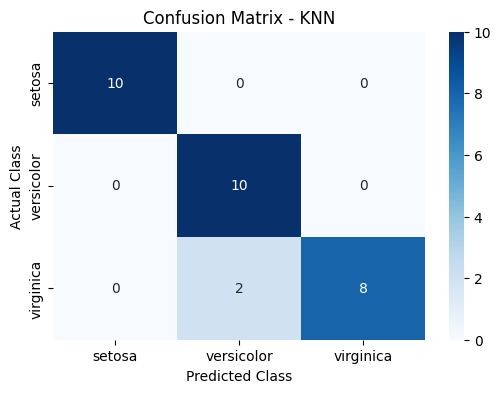

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score

# Create confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("\nAccuracy Score:", accuracy)

# Visualize confusion matrix
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Confusion Matrix - KNN")
plt.show()

**Explanation**: The confusion matrix compares actual and predicted classes. Accuracy measures the proportion of correctly classified test samples.
Accuracy = Correct Predictions / Total Predictions

**Step 5: Classification report**

In [ ]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(
    y_test, y_pred, target_names=iris.target_names
))

Classification Report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30



**Explanation**:

Precision: How many predicted samples of a class are actually that class.

Recall: How many actual samples of a class are correctly identified.

F1-score: Harmonic mean of precision and recall.

Support: Number of actual test samples belonging to each class.

**Step 6: Comparing error rate with K values**

In [ ]:
error_rates = []

for k in range(1, 21):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)

    predictions = model.predict(X_test)

    error = np.mean(predictions != y_test)
    error_rates.append(error)

print("K Value\tError Rate")

for k, error in enumerate(error_rates, start=1):
    print(f"{k}\t{error:.4f}")

K Value	Error Rate
1	0.0333
2	0.0667
3	0.0667
4	0.0667
5	0.0667
6	0.0667
7	0.0333
8	0.0667
9	0.0333
10	0.0333
11	0.0333
12	0.0333
13	0.0333
14	0.0333
15	0.0333
16	0.0333
17	0.0333
18	0.0333
19	0.0333
20	0.0333


**Explanation**:

The error rate represents the proportion of incorrectly classified samples.

Error Rate = 1 - Accuracy

We calculate the error rate for different K values ranging from 1 to 20. A lower error rate indicates better classification performance on the evaluated data.

**Step 7: Plot error values against K values**

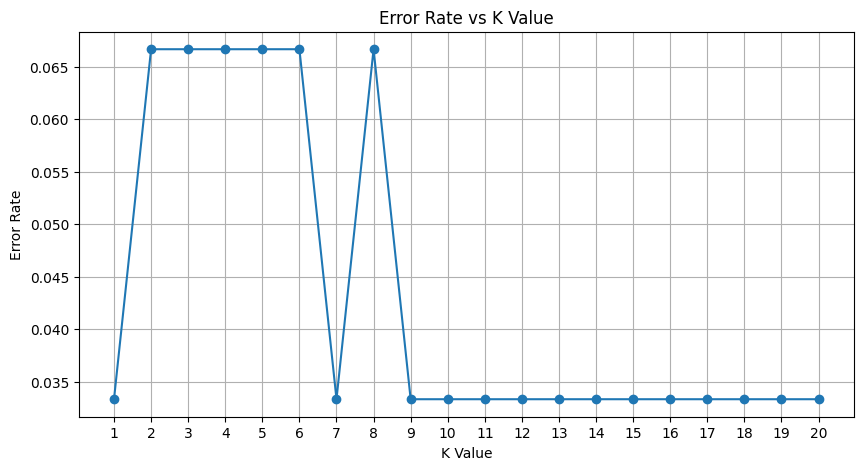

In [ ]:
k_values = range(1, 21)

plt.figure(figsize=(10, 5))
plt.plot(k_values, error_rates, marker="o")

plt.xlabel("K Value")
plt.ylabel("Error Rate")
plt.title("Error Rate vs K Value")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

**Explanation**: The graph helps us understand how the error rate changes as K increases. A very small K can be sensitive to noise, while a very large K can oversmooth the decision boundary.

**Step 8: Finding the best K**

Choose the K value that gives the minimum error rate among the tested values.

In [ ]:
best_k = np.argmin(error_rates) + 1
minimum_error = min(error_rates)

print("Best K Value:", best_k)
print("Minimum Error Rate:", minimum_error)
print("Best Accuracy:", 1 - minimum_error)

# Train the final model using the best K
best_knn = KNeighborsClassifier(n_neighbors=best_k)
best_knn.fit(X_train, y_train)

best_pred = best_knn.predict(X_test)

print("\nFinal Accuracy:",
      accuracy_score(y_test, best_pred))

Best K Value: 1
Minimum Error Rate: 0.03333333333333333
Best Accuracy: 0.9666666666666667

Final Accuracy: 0.9666666666666667


**Explanation**: np.argmin() returns the position of the minimum error rate. Adding 1 gives the corresponding K value because the tested values start at 1. If multiple values tie, this code selects the smallest K among them.

**Step 9: Visualize the KNN test results**

Since the Iris dataset has four features, we use Principal Component Analysis (PCA) to project the scaled test samples into two dimensions for visualization. The predictions still come from the KNN model trained on all four original features.

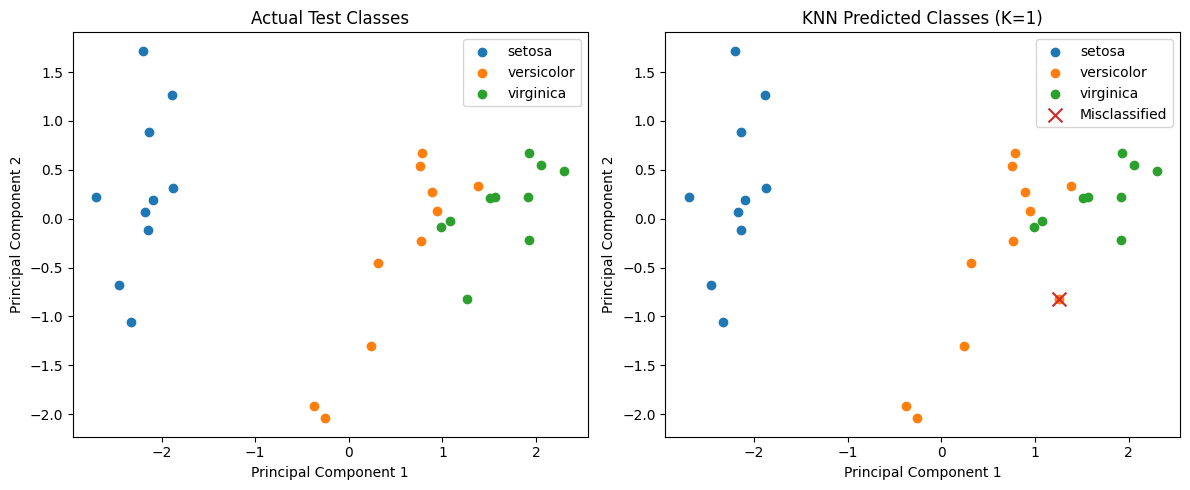

In [ ]:
from sklearn.decomposition import PCA

# Reduce test data to two dimensions for visualization
pca = PCA(n_components=2)
X_test_2d = pca.fit_transform(X_test)

# Plot actual classes and predicted classes
plt.figure(figsize=(12, 5))

# Actual test results
plt.subplot(1, 2, 1)
for i, name in enumerate(iris.target_names):
    mask = y_test == i
    plt.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        label=name
    )

plt.title("Actual Test Classes")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

# Predicted test results
plt.subplot(1, 2, 2)
for i, name in enumerate(iris.target_names):
    mask = best_pred == i
    plt.scatter(
        X_test_2d[mask, 0],
        X_test_2d[mask, 1],
        label=name
    )

# Highlight incorrectly classified samples
wrong = best_pred != y_test

plt.scatter(
    X_test_2d[wrong, 0],
    X_test_2d[wrong, 1],
    marker="x",
    s=100,
    label="Misclassified"
)

plt.title(f"KNN Predicted Classes (K={best_k})")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

plt.tight_layout()
plt.show()

**Explanation**: The first graph shows the actual flower classes, while the second shows the classes predicted by KNN. Misclassified samples are marked with crosses. PCA is used only to display the results in two dimensions; it does not change the model's predictions.

**Conclusion**:

In this practical, we successfully implemented the K-Nearest Neighbors (KNN) classification algorithm using the Iris dataset.

We performed exploratory data analysis, divided the dataset into training and testing sets, and applied feature scaling using StandardScaler.

The model was trained using K=5 and achieved an accuracy of 93.33%. We also compared different K values from 1 to 20 and identified K=1 as the value with the lowest error rate in our experiment.

Finally, we used PCA to visualize the actual and predicted flower classes.

This practical helped us understand how KNN works, how the value of K affects classification, and how to evaluate a machine learning model.